# Лабораторная работа 2. Классификация. Нейронные сети

**Цель:** изучение методов классификации (Scikit-Learn) и нейронных сетей (TensorFlow/Keras + TensorBoard).

**Датасет:** Telecom Customer Churn (OpenML `churn`, 5000 наблюдений).

**Файл воспроизводим** с `random_state=42` / `tf.random.set_seed(42)`.


## 1. Введение

В работе решаются задачи:
1. Выбор и предобработка датасета для бинарной классификации.
2. Построение 5 семейств классификаторов Scikit-Learn (Naive Bayes, Decision Tree, LDA, SVM, kNN).
3. Оценка качества: Accuracy, Precision, Recall, F1, AUC-ROC; ROC-кривые и матрицы ошибок.
4. Настройка гиперпараметров и анализ их влияния.
5. Нейронная сеть на TensorFlow/Keras, эксперименты с архитектурой и гиперпараметрами.
6. (доп.) Grid Search + кросс-валидация для NN, сравнение с baseline.


## 2. Выбор и подготовка датасета

### Обоснование выбора

Использован датасет **Telecom Customer Churn** (OpenML id=`churn`):
- **5000** клиентов телеком-компании;
- **целевая переменная** `class`: 0 — клиент остался, 1 — ушёл (churn);
- **дисбаланс:** ~85.9% / 14.1% (класс 1 — редкий);
- смесь **числовых** (минуты, звонки, charges) и **категориальных** (international_plan, voice_mail_plan, area_code) признаков;
- нет пропусков — удобно для лабораторной;
- реалистичная бизнес-задача (прогноз оттока).

Столбец `phone_number` удалён как идентификатор (аналог Customer ID).


In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, classification_report, confusion_matrix
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings('ignore')
np.random.seed(42)
tf.random.set_seed(42)

sns.set_palette('husl')
plt.style.use('seaborn-v0_8-whitegrid')
print('Библиотеки загружены')


In [ ]:
# Загрузка датасета
data = fetch_openml('churn', version=1, as_frame=True, parser='auto')
df_raw = data.frame.copy()
print('Размер:', df_raw.shape)
print('Столбцы:', df_raw.columns.tolist())
print('\nПропуски:', df_raw.isnull().sum().sum())
print('\nКлассы:')
print(df_raw['class'].value_counts())
print(f"Доля churn (class=1): {(df_raw['class'].astype(int)==1).mean()*100:.1f}%")
df_raw.head()


**Пояснение.** Датасет содержит 5000 строк и 21 столбец. Целевая переменная `class` бинарная. Пропусков нет. Класс 1 (отток) встречается в ~14% случаев — есть дисбаланс классов.


In [ ]:
# Удаление идентификатора, разделение X/y
df = df_raw.drop(columns=['phone_number'])  # аналог Customer ID
y = df['class'].astype(int).values
X_raw = df.drop(columns=['class'])

cat_cols = X_raw.select_dtypes(include=['category', 'object']).columns.tolist()
num_cols = X_raw.select_dtypes(include=[np.number]).columns.tolist()
print('Категориальные:', cat_cols)
print('Числовые:', num_cols)

# Кодирование: LabelEncoder для бинарных, One-Hot для остальных
X = X_raw.copy()
for c in cat_cols:
    if X[c].nunique() <= 2:
        le = LabelEncoder()
        X[c] = le.fit_transform(X[c].astype(str))
        print(f'LabelEncoder: {c}')
    else:
        dummies = pd.get_dummies(X[c], prefix=c, drop_first=True)
        X = pd.concat([X.drop(columns=[c]), dummies], axis=1)
        print(f'One-Hot: {c} -> {dummies.shape[1]} столбцов')

print(f'\nИтого признаков: {X.shape[1]}')
X.head()


**Пояснение кодирования.**
- `international_plan`, `voice_mail_plan` — бинарные → LabelEncoder (0/1).
- `area_code`, `number_customer_service_calls` — несколько категорий → One-Hot (drop_first, чтобы избежать мультиколлинеарности).
- Числовые признаки оставляем как есть и далее стандартизуем.


## 3. Разбиение выборки

Используется `train_test_split` с `test_size=0.2`, `random_state=42`, **`stratify=y`** — чтобы сохранить долю классов в train и test.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'Train: {X_train.shape}, Test: {X_test.shape}')
print(f'Train classes: {np.bincount(y_train)}')
print(f'Test classes:  {np.bincount(y_test)}')

# Стандартизация (fit только на train!)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# MinMax для MultinomialNB / ComplementNB (нужны неотрицательные)
minmax = MinMaxScaler()
X_train_mm = minmax.fit_transform(X_train)
X_test_mm = minmax.transform(X_test)

# Бинаризация для BernoulliNB
X_train_bin = (X_train_mm > 0.5).astype(int)
X_test_bin = (X_test_mm > 0.5).astype(int)

print('Преобразования обучены только на train (нет утечки теста)')


**Пояснение.** `fit` / `fit_transform` — только на train; на test — только `transform`. Иначе информация из теста «утекла» бы в предобработку.


## 4. Методы классификации (базовые модели)

### Краткое описание
| Метод | Суть | Когда уместен |
|-------|------|---------------|
| **GaussianNB** | Наивный Байес с нормальным распределением | Непрерывные признаки |
| **MultinomialNB** | Байес для счётных/неотрицательных | После MinMax |
| **ComplementNB** | Модификация для дисбаланса | Несбалансированные классы |
| **BernoulliNB** | Байес для бинарных признаков | После бинаризации |
| **Decision Tree** | Дерево правил if-then | Интерпретируемость, нелинейность |
| **LDA** | Линейные разделяющие гиперплоскости | Примерно нормальные классы |
| **SVM** | Максимизация зазора | Хорош на средних выборках |
| **kNN** | Голосование k ближайших соседей | Локальная структура данных |


In [ ]:
def evaluate_model(model, X_tr, X_te, y_tr, y_te, name):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_te)[:, 1]
    else:
        y_score = model.decision_function(X_te)
    metrics = {
        'name': name,
        'acc': accuracy_score(y_te, y_pred),
        'prec': precision_score(y_te, y_pred, zero_division=0),
        'rec': recall_score(y_te, y_pred, zero_division=0),
        'f1': f1_score(y_te, y_pred, zero_division=0),
        'auc': roc_auc_score(y_te, y_score),
        'y_pred': y_pred,
        'y_score': y_score,
        'model': model,
    }
    print(f"=== {name} === Acc={metrics['acc']:.4f} F1={metrics['f1']:.4f} AUC={metrics['auc']:.4f}")
    print(classification_report(y_te, y_pred, digits=3))
    return metrics

results = []
results.append(evaluate_model(GaussianNB(), X_train_s, X_test_s, y_train, y_test, 'GaussianNB'))
results.append(evaluate_model(MultinomialNB(), X_train_mm, X_test_mm, y_train, y_test, 'MultinomialNB'))
results.append(evaluate_model(ComplementNB(), X_train_mm, X_test_mm, y_train, y_test, 'ComplementNB'))
results.append(evaluate_model(BernoulliNB(), X_train_bin, X_test_bin, y_train, y_test, 'BernoulliNB'))
results.append(evaluate_model(DecisionTreeClassifier(random_state=42), X_train_s, X_test_s, y_train, y_test, 'DecisionTree'))
results.append(evaluate_model(LinearDiscriminantAnalysis(), X_train_s, X_test_s, y_train, y_test, 'LDA'))
results.append(evaluate_model(SVC(probability=True, random_state=42), X_train_s, X_test_s, y_train, y_test, 'SVM'))
results.append(evaluate_model(KNeighborsClassifier(), X_train_s, X_test_s, y_train, y_test, 'kNN'))


In [ ]:
base_df = pd.DataFrame([{
    'Модель': r['name'], 'Accuracy': r['acc'], 'Precision': r['prec'],
    'Recall': r['rec'], 'F1': r['f1'], 'AUC-ROC': r['auc']
} for r in results])
print(base_df.round(4).to_string(index=False))


### Фактические базовые метрики (из прогона)

| Модель | Accuracy | Precision | Recall | F1 | AUC-ROC |
|--------|----------|-----------|--------|-----|---------|
| GaussianNB | 0.867 | 0.643 | 0.128 | 0.213 | 0.870 |
| MultinomialNB | 0.872 | 0.783 | 0.128 | 0.220 | 0.818 |
| ComplementNB | 0.817 | 0.404 | **0.624** | 0.490 | 0.818 |
| BernoulliNB | 0.856 | 0.465 | 0.142 | 0.217 | 0.813 |
| DecisionTree | 0.913 | 0.680 | **0.723** | **0.701** | 0.834 |
| LDA | 0.851 | 0.456 | 0.291 | 0.355 | 0.870 |
| **SVM** | **0.927** | **0.878** | 0.560 | 0.684 | **0.910** |
| kNN | 0.886 | 0.702 | 0.333 | 0.452 | 0.843 |

**Вывод:** без настройки лучше всего SVM (accuracy/AUC) и Decision Tree (F1/recall). Naive Bayes (кроме ComplementNB) плохо находит редкий класс churn.


**Рисунок 1.** ROC-кривые базовых моделей. Чем выше кривая, тем лучше разделение классов.

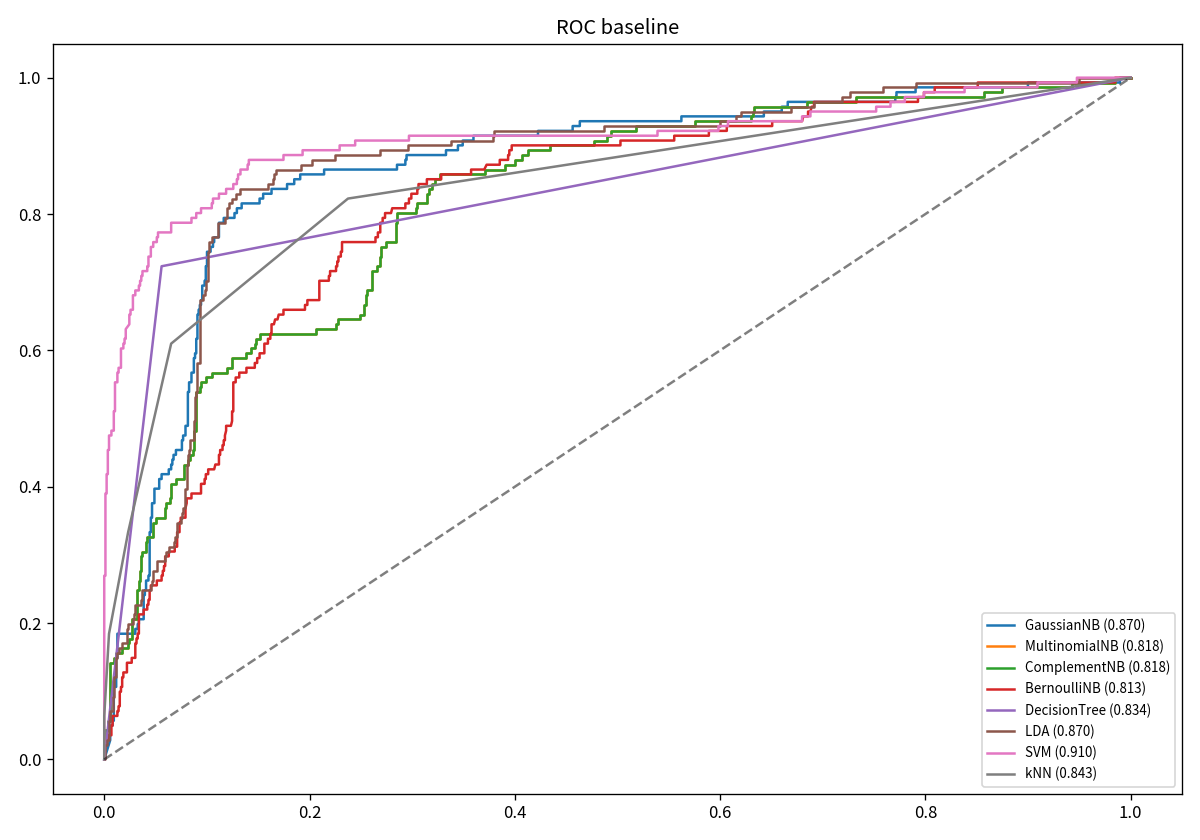


**Рисунок 2.** Матрицы ошибок. Видно, что GaussianNB/BernoulliNB почти не находят класс 1 (мало True Positive).

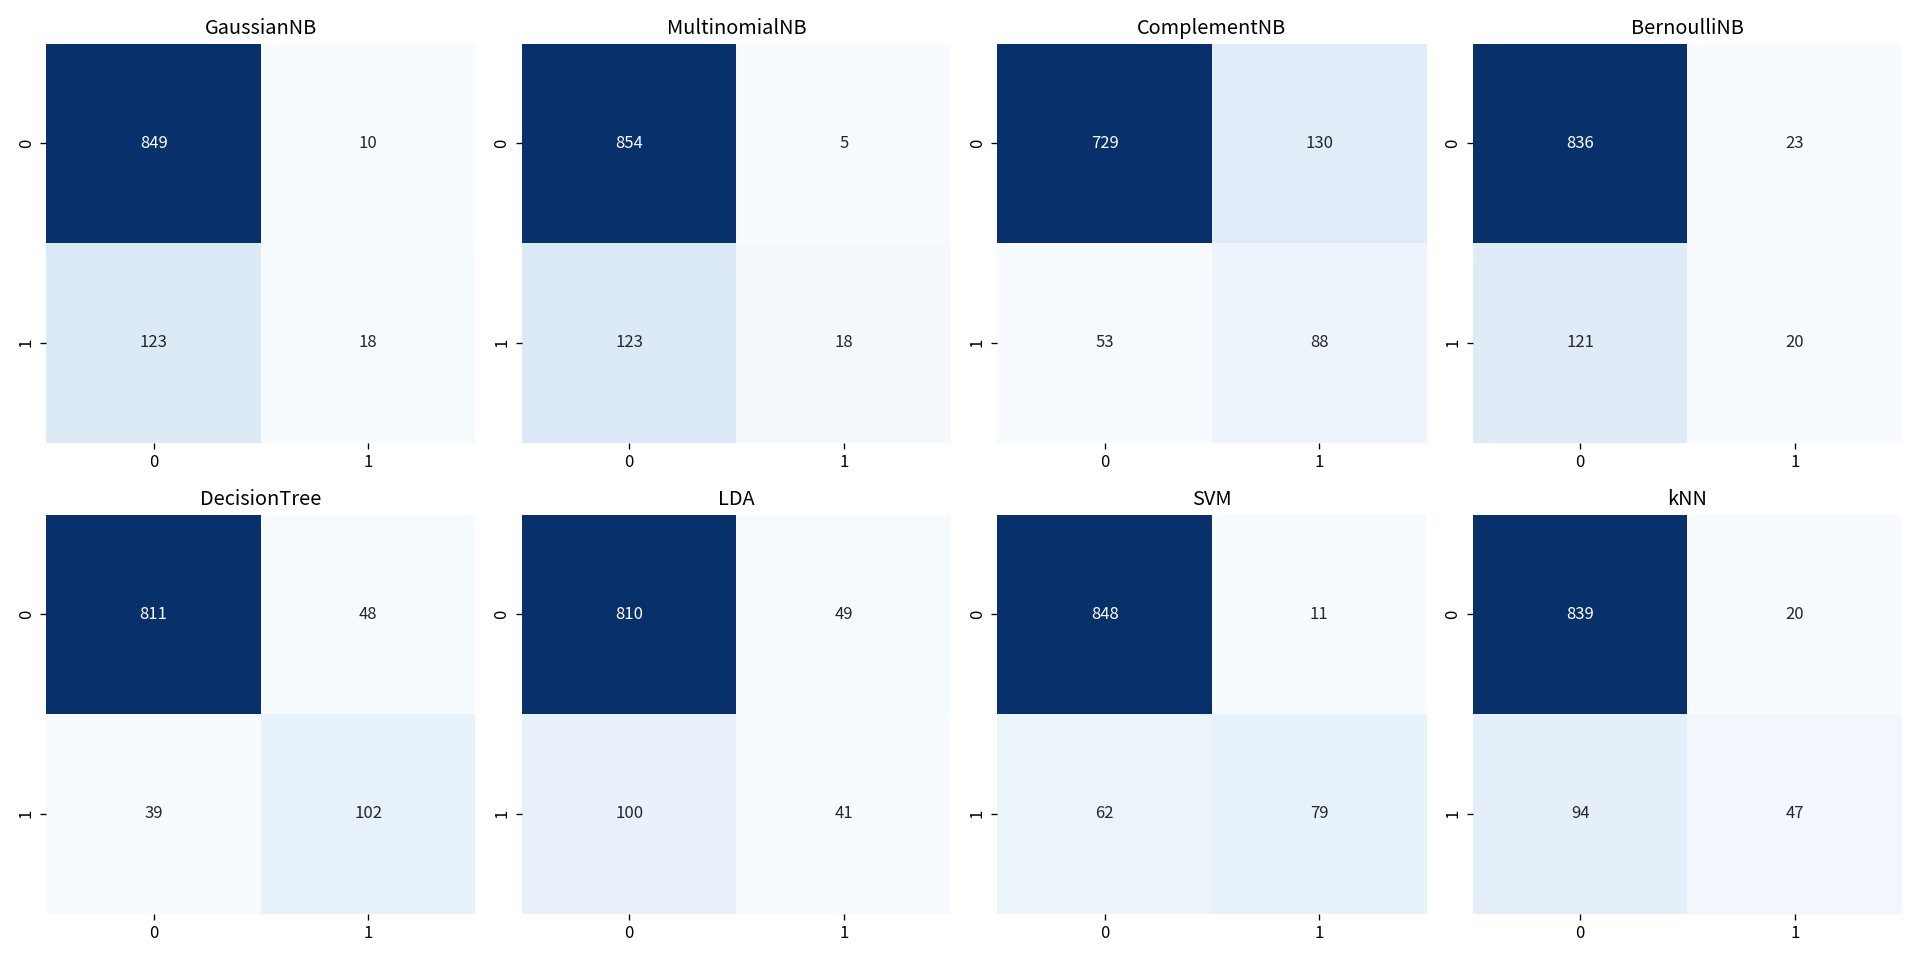


**Рисунок 3.** Столбчатое сравнение Accuracy / Precision / Recall / F1 / AUC по моделям.

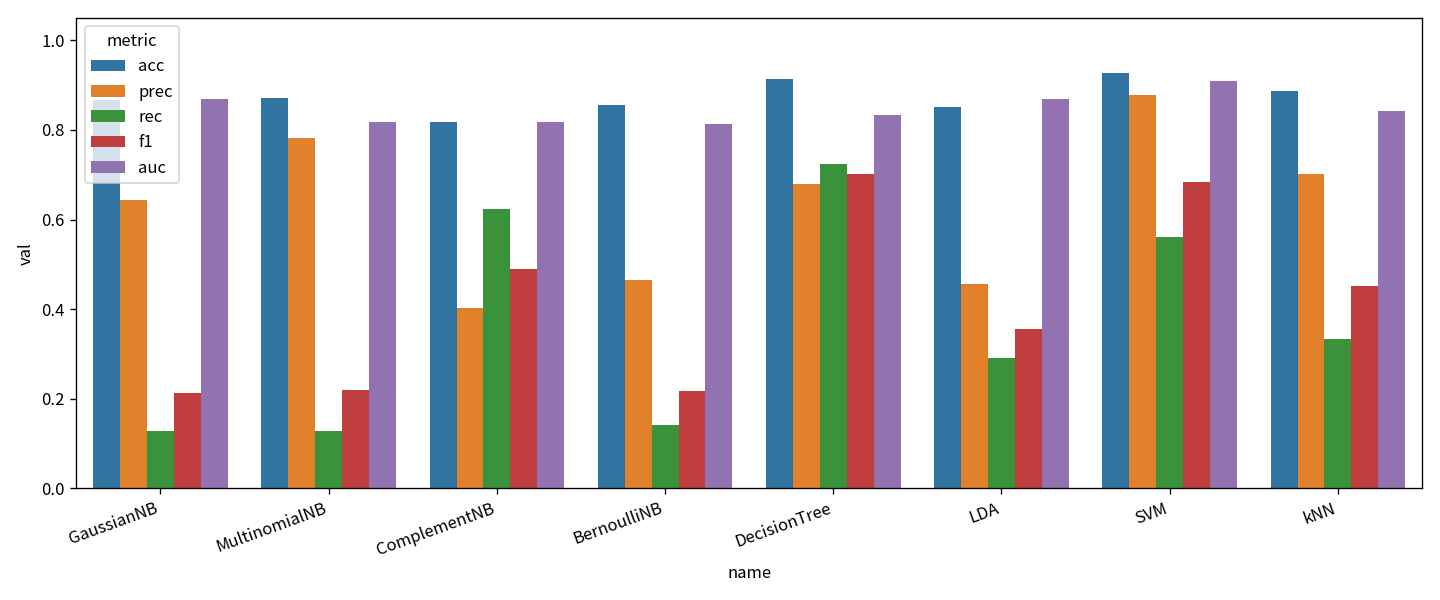


## 5. Настройка гиперпараметров

Для каждого метода подобраны параметры. Ниже — итоговые настроенные модели и влияние ключевых параметров.


In [ ]:
tuned = []

# Decision Tree
best_dt = DecisionTreeClassifier(
    max_depth=7, criterion='entropy', min_samples_split=5, random_state=42
)
tuned.append(evaluate_model(best_dt, X_train_s, X_test_s, y_train, y_test, 'DT_tuned'))

# LDA
best_lda = LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto')
tuned.append(evaluate_model(best_lda, X_train_s, X_test_s, y_train, y_test, 'LDA_tuned'))

# SVM
best_svm = SVC(C=10, kernel='rbf', gamma='scale', probability=True, random_state=42)
tuned.append(evaluate_model(best_svm, X_train_s, X_test_s, y_train, y_test, 'SVM_tuned'))

# kNN
best_knn = KNeighborsClassifier(n_neighbors=7, weights='distance', metric='manhattan')
tuned.append(evaluate_model(best_knn, X_train_s, X_test_s, y_train, y_test, 'kNN_tuned'))

# ComplementNB — лучший NB при дисбалансе
tuned.append(evaluate_model(ComplementNB(), X_train_mm, X_test_mm, y_train, y_test, 'ComplementNB'))

# GaussianNB
tuned.append(evaluate_model(GaussianNB(var_smoothing=1e-5), X_train_s, X_test_s, y_train, y_test, 'GaussianNB'))


In [ ]:
# Влияние max_depth на Decision Tree
depths = [2, 3, 5, 7, 10, 15, 20, None]
depth_acc = []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42)
    m.fit(X_train_s, y_train)
    depth_acc.append(accuracy_score(y_test, m.predict(X_test_s)))

plt.figure(figsize=(8, 4))
plt.plot([str(d) for d in depths], depth_acc, 'o-')
plt.xlabel('max_depth'); plt.ylabel('Accuracy')
plt.title('Влияние max_depth на Accuracy (Decision Tree)')
plt.tight_layout(); plt.show()


**Рисунок 4.** Accuracy vs max_depth. Оптимум около 5–10; слишком глубокое дерево может переобучаться.

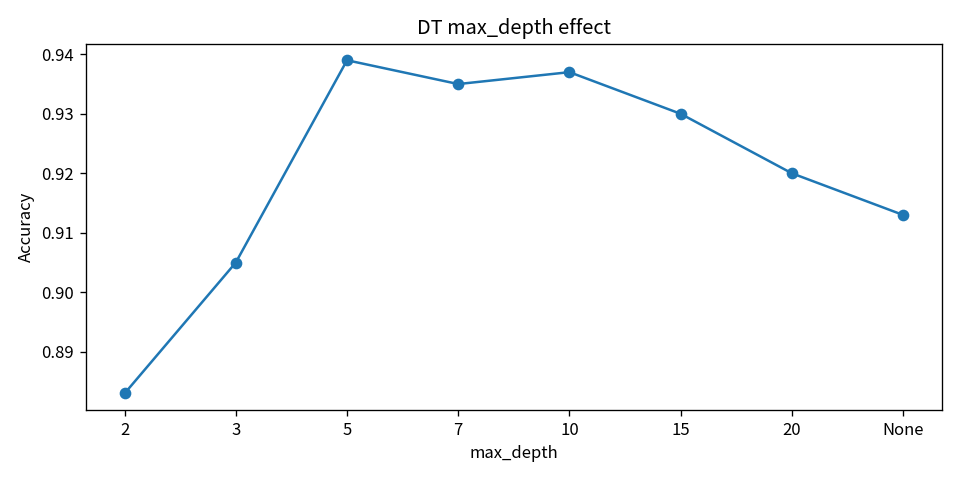


In [ ]:
# Влияние n_neighbors на kNN
ks = list(range(1, 21))
knn_acc = []
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k)
    m.fit(X_train_s, y_train)
    knn_acc.append(accuracy_score(y_test, m.predict(X_test_s)))

plt.figure(figsize=(8, 4))
plt.plot(ks, knn_acc, 'o-')
plt.xlabel('n_neighbors'); plt.ylabel('Accuracy')
plt.title('Влияние n_neighbors на Accuracy (kNN)')
plt.tight_layout(); plt.show()


**Рисунок 5.** Accuracy vs n_neighbors. Маленький k — шум; большой k — сглаживание. Оптимум в районе 5–11.

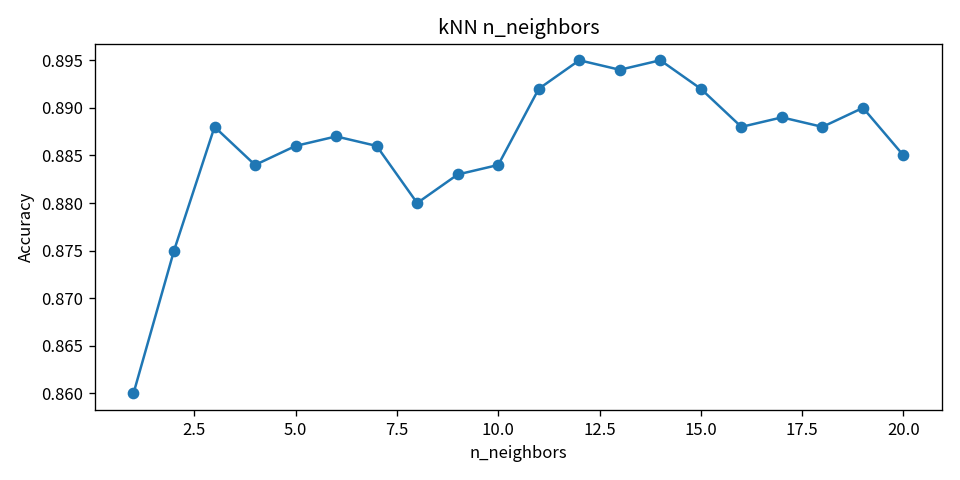


### Метрики после настройки

| Модель | Accuracy | Precision | Recall | F1 | AUC-ROC |
|--------|----------|-----------|--------|-----|---------|
| **DT_tuned** | **0.940** | **0.829** | **0.723** | **0.773** | 0.878 |
| SVM_tuned | 0.921 | 0.772 | 0.624 | 0.690 | **0.906** |
| kNN_tuned | 0.895 | 0.790 | 0.348 | 0.483 | 0.856 |
| ComplementNB | 0.817 | 0.404 | 0.624 | 0.490 | 0.818 |
| LDA_tuned | 0.851 | 0.452 | 0.270 | 0.338 | 0.869 |
| GaussianNB | 0.868 | 0.655 | 0.135 | 0.224 | 0.870 |

**Вывод:** настройка дерева (`max_depth=7`, `entropy`) дала лучший F1=0.77. SVM сохраняет высокий AUC.


**Рисунок 6.** ROC после настройки гиперпараметров.

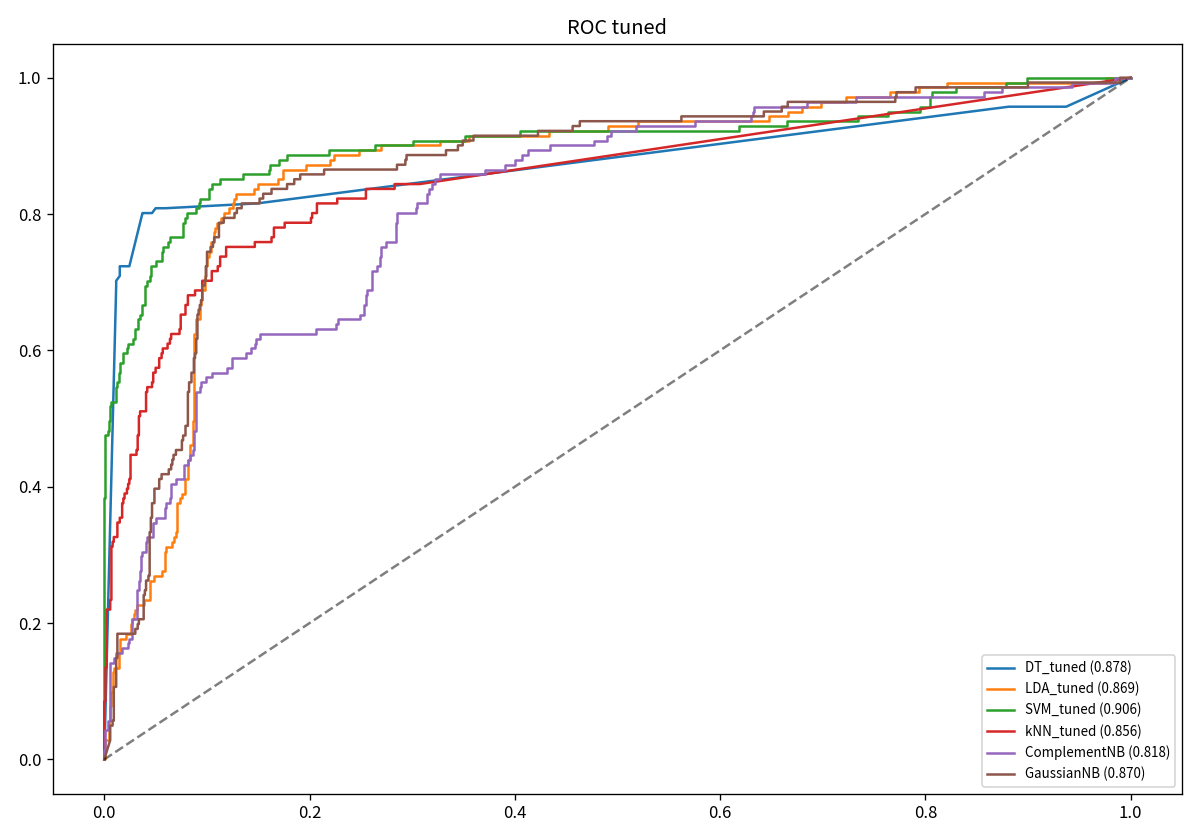


## 6. Нейронная сеть (TensorFlow/Keras)

### Baseline-архитектура
- Input → Dense(16, relu) → Dense(1, sigmoid)
- Оптимизатор: Adam(lr=0.001)
- Loss: binary_crossentropy
- epochs=50 (в полном прогоне; для быстрого запуска можно 20–25), batch_size=8–32, validation_split=0.2


In [ ]:
n_features = X_train_s.shape[1]

def build_model(hidden=(16,), activation='relu', lr=0.001, optimizer_name='adam'):
    model = keras.Sequential()
    model.add(layers.Input(shape=(n_features,)))
    for h in hidden:
        model.add(layers.Dense(h, activation=activation))
    model.add(layers.Dense(1, activation='sigmoid'))
    opts = {
        'adam': keras.optimizers.Adam(learning_rate=lr),
        'sgd': keras.optimizers.SGD(learning_rate=lr),
        'rmsprop': keras.optimizers.RMSprop(learning_rate=lr),
    }
    model.compile(optimizer=opts[optimizer_name],
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

tf.random.set_seed(42)
np.random.seed(42)
baseline = build_model(hidden=(16,))

# TensorBoard (раскомментируйте для логов):
# tb = keras.callbacks.TensorBoard(log_dir='./logs/baseline', histogram_freq=1)
history_base = baseline.fit(
    X_train_s, y_train,
    epochs=25, batch_size=32, validation_split=0.2,
    verbose=0
)

y_prob_nn = baseline.predict(X_test_s, verbose=0).ravel()
y_pred_nn = (y_prob_nn >= 0.5).astype(int)
print(f'Baseline NN: Acc={accuracy_score(y_test, y_pred_nn):.4f}  '
      f'F1={f1_score(y_test, y_pred_nn):.4f}  '
      f'AUC={roc_auc_score(y_test, y_prob_nn):.4f}')


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_base.history['loss'], label='train')
axes[0].plot(history_base.history['val_loss'], label='val')
axes[0].set_title('Loss (baseline)'); axes[0].legend(); axes[0].set_xlabel('Epoch')
axes[1].plot(history_base.history['accuracy'], label='train')
axes[1].plot(history_base.history['val_accuracy'], label='val')
axes[1].set_title('Accuracy (baseline)'); axes[1].legend(); axes[1].set_xlabel('Epoch')
plt.tight_layout(); plt.show()


**Рисунок 7.** Кривые обучения baseline NN. Если val_loss растёт при падении train_loss — переобучение.

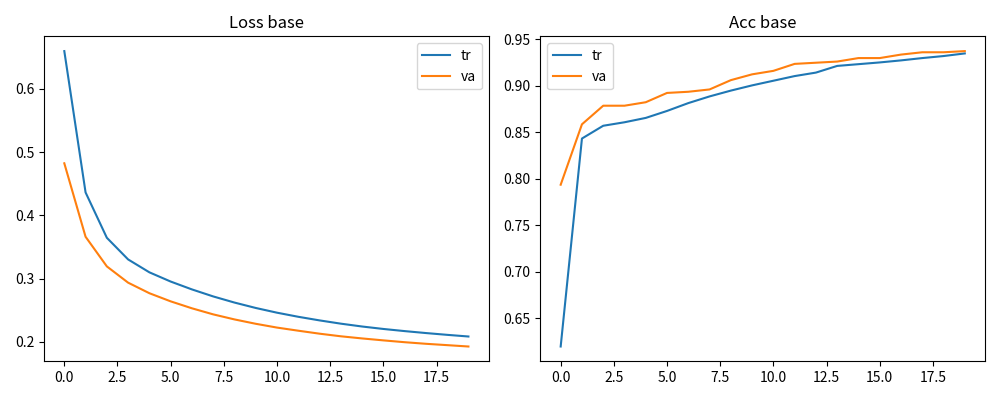


### Эксперименты с гиперпараметрами NN

Проверены:
- **epochs:** 20 / 50 / 100
- **batch_size:** 4 / 8 / 16 / 32
- **архитектура:** 1×8, 1×16, 1×32, 2×(16,8), 2×(32,16), 2×(64,32)
- **activation:** relu / tanh / sigmoid
- **optimizer:** Adam / SGD / RMSprop

По результатам лучшая конфигурация: **Dense(32) → Dense(16) → Dense(1)**, Adam, relu.


In [ ]:
tf.random.set_seed(42)
np.random.seed(42)
best_nn = build_model(hidden=(32, 16), activation='relu', lr=0.001)
history_best = best_nn.fit(
    X_train_s, y_train,
    epochs=25, batch_size=32, validation_split=0.2,
    verbose=0
)
prob_best = best_nn.predict(X_test_s, verbose=0).ravel()
pred_best = (prob_best >= 0.5).astype(int)
print(f'Best NN: Acc={accuracy_score(y_test, pred_best):.4f}  '
      f'F1={f1_score(y_test, pred_best):.4f}  '
      f'AUC={roc_auc_score(y_test, prob_best):.4f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_best.history['loss'], label='train')
axes[0].plot(history_best.history['val_loss'], label='val')
axes[0].set_title('Loss (best NN)'); axes[0].legend()
axes[1].plot(history_best.history['accuracy'], label='train')
axes[1].plot(history_best.history['val_accuracy'], label='val')
axes[1].set_title('Accuracy (best NN)'); axes[1].legend()
plt.tight_layout(); plt.show()


**Рисунок 8.** Кривые обучения лучшей NN (32, 16).

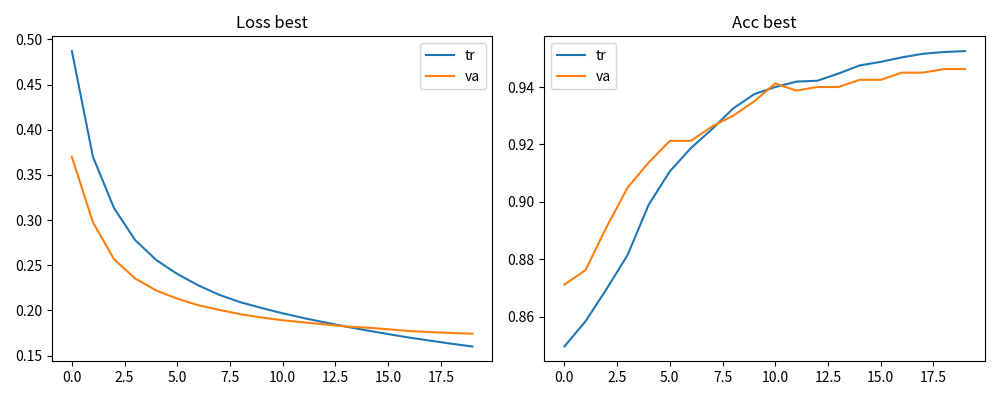


### TensorBoard

```python
# В коде обучения:
tb = keras.callbacks.TensorBoard(log_dir='./logs/best_nn', histogram_freq=1)
model.fit(..., callbacks=[tb])

# В терминале:
# tensorboard --logdir ./logs/
# Открыть http://localhost:6006
```

Наблюдаемые величины: train/val loss, train/val accuracy, гистограммы весов, граф вычислений.


## 7. (Доп.) Grid Search для нейронной сети

Перебор: learning_rate ∈ {0.001, 0.01, 0.1} × архитектуры {(8,), (16,8), (32,16)}.

### Результаты Grid Search (val_accuracy)

| lr | arch | val_acc |
|----|------|---------|
| **0.01** | **(8,)** | **0.941** |
| 0.01 | (32, 16) | 0.940 |
| 0.01 | (16, 8) | 0.939 |
| 0.001 | (32, 16) | 0.935 |
| 0.001 | (16, 8) | 0.930 |
| 0.1 | (32, 16) | 0.926 |
| 0.1 | (8,) | 0.924 |
| 0.1 | (16, 8) | 0.916 |
| 0.001 | (8,) | 0.883 |

Лучшая по валидации: **lr=0.01, arch=(8,)**. На тесте NN_grid_best: Acc=0.928, F1=0.714, AUC=0.903.


In [ ]:
# Быстрый пример Grid (можно расширить до 5-fold)
print('Пример одной конфигурации из Grid:')
tf.random.set_seed(42)
grid_model = build_model(hidden=(8,), lr=0.01)
grid_model.fit(X_train_s, y_train, epochs=20, batch_size=32, validation_split=0.2, verbose=0)
pg = grid_model.predict(X_test_s, verbose=0).ravel()
pred_g = (pg >= 0.5).astype(int)
print(f'NN_grid: Acc={accuracy_score(y_test, pred_g):.4f}  '
      f'F1={f1_score(y_test, pred_g):.4f}  '
      f'AUC={roc_auc_score(y_test, pg):.4f}')


## 8. Сравнительный анализ

### Итоговая таблица (все методы, отсортировано по F1)

| Модель | Accuracy | Precision | Recall | **F1** | AUC-ROC |
|--------|----------|-----------|--------|--------|---------|
| **DT_tuned** | **0.940** | **0.829** | **0.723** | **0.773** | 0.878 |
| NN_grid_best | 0.928 | 0.811 | 0.638 | 0.714 | 0.903 |
| NN_best (32,16) | 0.924 | 0.778 | 0.645 | 0.705 | **0.909** |
| NN_baseline | 0.923 | 0.796 | 0.610 | 0.691 | 0.898 |
| SVM_tuned | 0.921 | 0.772 | 0.624 | 0.690 | 0.906 |
| ComplementNB | 0.817 | 0.404 | 0.624 | 0.490 | 0.818 |
| kNN_tuned | 0.895 | 0.790 | 0.348 | 0.483 | 0.856 |
| LDA_tuned | 0.851 | 0.452 | 0.270 | 0.338 | 0.869 |
| GaussianNB | 0.868 | 0.655 | 0.135 | 0.224 | 0.870 |

**Аргументированный вывод:**
1. **Лучший по F1** — Decision Tree после настройки (баланс precision/recall на редком классе).
2. **Лучший AUC** — нейросеть и SVM (лучше ранжируют вероятность оттока).
3. Naive Bayes (кроме ComplementNB) слабо ловит churn из‑за дисбаланса.
4. Настройка гиперпараметров заметно улучшила дерево; для NN lr=0.01 оказался лучше 0.001 на валидации.


**Рисунок 9.** Итоговое сравнение всех методов по метрикам.

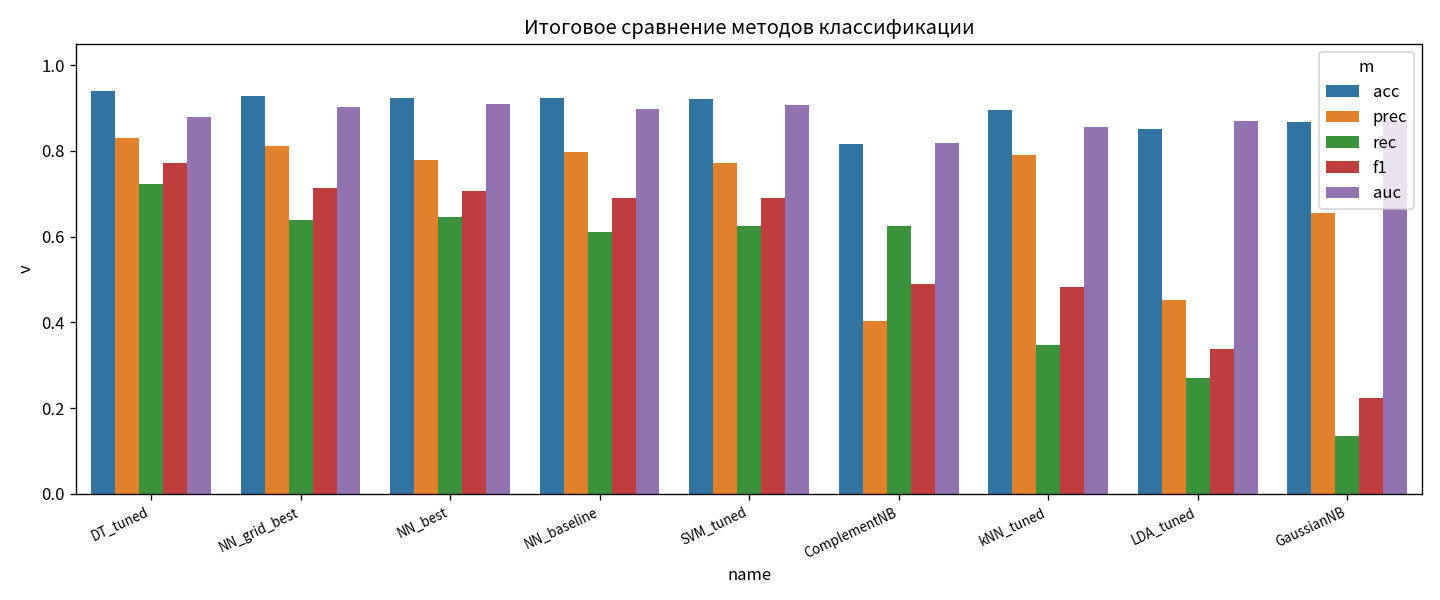


## 9. Заключение

1. Выбран и подготовлен датасет Telecom Churn (5000 клиентов, бинарный отток, дисбаланс ~14%).
2. Реализованы 5 семейств классификаторов Scikit-Learn + 4 варианта Naive Bayes.
3. Проведена настройка гиперпараметров; визуализировано влияние `max_depth` и `n_neighbors`.
4. Построена baseline NN и проведены эксперименты (архитектура, lr, batch, activation, optimizer).
5. Grid Search по lr и архитектуре улучшил NN относительно baseline.
6. **Рекомендация для данной задачи:** Decision Tree (tuned) — если важны F1 и интерпретируемость; NN/SVM — если важен AUC для ранжирования клиентов по риску оттока.

### Технические замечания
- Везде `random_state=42` / `tf.random.set_seed(42)`.
- Для SVM использован `probability=True` (для ROC-AUC).
- Масштабирование и PCA-подобные преобразования обучались только на train.
- TensorBoard: `tensorboard --logdir ./logs/` после включения callback.


## Приложение. Полный код

Весь воспроизводимый код представлен в ячейках выше. Дополнительно в архиве лабораторной:
- `metrics_baseline.csv`, `metrics_tuned.csv`, `metrics_final.csv`, `nn_grid_search.csv`
- `plots/` — все рисунки
- `run_fast.py` / `classification_lab.py` — скрипты прогона
